# FitBit Usage Analysis

In [1]:
import pandas as pd

## Import semua data yang sudah dihitung

In [2]:
df_daily_activity = pd.read_csv('usage_1_daily_activity.csv')
df_heart_rate = pd.read_csv('usage_2_heart_rate.csv')
df_hourly_calories = pd.read_csv('usage_3_hourly_calories.csv')
df_hourly_intensities = pd.read_csv('usage_4_hourly_intensities.csv')
df_hourly_steps = pd.read_csv('usage_5_hourly_steps.csv')
df_minutes_calories = pd.read_csv('usage_6_minutes_calories.csv')
df_minute_intensities = pd.read_csv('usage_7_minutes_intensities.csv')
df_METs = pd.read_csv('usage_8_METs.csv')
df_minute_sleep = pd.read_csv('usage_9_minute_sleep.csv')
df_minute_steps = pd.read_csv('usage_10_minute_steps.csv')
df_weight = pd.read_csv('usage_11_weight_login.csv')

In [3]:
df_all_usage = pd.concat([
    df_daily_activity,
    df_heart_rate,
    df_hourly_calories,
    df_hourly_intensities,
    df_hourly_steps,
    df_minutes_calories,
    df_minute_intensities,
    df_METs,
    df_minute_sleep,
    df_minute_steps,
    df_weight
], ignore_index=True)

In [4]:
df_all_usage

,user_id,date
0,1503960366,2016-03-25
1,1503960366,2016-03-26
2,1503960366,2016-03-27
3,1503960366,2016-03-28
4,1503960366,2016-03-29
...,...,...
8242,8877689391,2016-04-07
8243,8877689391,2016-04-08
8244,8877689391,2016-04-09
8245,8877689391,2016-04-11


In [5]:
df_all_usage['date'].nunique()

33

### Per user menggunakan FitBit berapa hari?

In [6]:
df_total_usage = df_all_usage.groupby('user_id')['date'].nunique().reset_index(name='total_usage_days').sort_values('total_usage_days',ascending=False).reset_index(drop=True)
df_total_usage

,user_id,total_usage_days
0,2347167796,33
1,2026352035,33
2,1927972279,33
3,6962181067,33
4,8378563200,33
5,4702921684,33
6,1503960366,32
7,8253242879,32
8,1624580081,32
9,2022484408,32


In [7]:
df_total_usage['total_usage_days'].median()

32.0

In [8]:
df_total_usage['user_type'] = ''

for i in df_total_usage.index:
    if df_total_usage.loc[i, 'total_usage_days'] > 32:
        df_total_usage.loc[i, 'user_type'] = 'High-Usage User'

    elif df_total_usage.loc[i, 'total_usage_days'] == 32:
        df_total_usage.loc[i, 'user_type'] = 'Moderate-Usage User'

    else:
        df_total_usage.loc[i, 'user_type'] = 'Low-Usage User'

df_total_usage

,user_id,total_usage_days,user_type
0,2347167796,33,High-Usage User
1,2026352035,33,High-Usage User
2,1927972279,33,High-Usage User
3,6962181067,33,High-Usage User
4,8378563200,33,High-Usage User
5,4702921684,33,High-Usage User
6,1503960366,32,Moderate-Usage User
7,8253242879,32,Moderate-Usage User
8,1624580081,32,Moderate-Usage User
9,2022484408,32,Moderate-Usage User


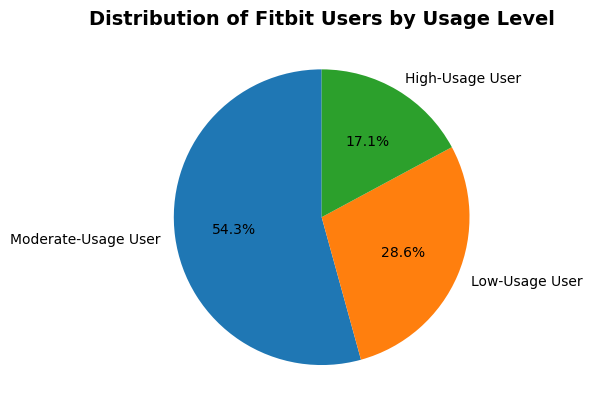

In [9]:
import matplotlib.pyplot as plt

df_total_usage['user_type'].value_counts().plot(
    kind='pie',
    startangle=90,
    autopct='%1.1f%%'
)

plt.ylabel('')
plt.title(
    'Distribution of Fitbit Users by Usage Level',
    fontsize=14,
    fontweight='bold'
)
plt.show()

In [10]:
# Download Hasil

df_total_usage.to_csv('total_usage.csv')

### Per Hari ada berapa user yang pakai?

In [11]:
df_total_usage_per_date = df_all_usage.groupby('date')['user_id'].nunique().reset_index(name='total_usage_per_date')
df_total_usage_per_date

,date,total_usage_per_date
0,2016-03-11,10
1,2016-03-12,33
2,2016-03-13,33
3,2016-03-14,33
4,2016-03-15,33
5,2016-03-16,33
6,2016-03-17,33
7,2016-03-18,33
8,2016-03-19,33
9,2016-03-20,33
